# 07 · The cancellation model

The policy needs, for every request, the probability that the guest will cancel. That number is
used directly in the money calculation: a booking with `p_cancel = 0.3` occupies 0.7 of a room in
expectation. So the model is judged first on **calibration** and **log-loss**, and only then on
ranking (AUC); accuracy at a threshold is irrelevant.

This notebook covers the feature set, the validation design, the comparison of algorithms, the
ablations that justify each exclusion, and the link between probability quality and revenue.
All numbers come from scripts in `experiments/` (outputs in `experiments/results/`), run on
`train.csv` only.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train
from src.features import FeatureBuilder, stream_features
from src.stream_model import MODEL_CFG
from src.explain import label, theme
from src import plotting as P

P.setup()
pd.set_option("display.width", 180)
R = Path("..") / "experiments" / "results"
RECIPE_NAMES = {"lr": "Logistic regression", "lgb": "LightGBM", "cb": "CatBoost", "ebm": "EBM (compared)",
                "avg3": "Average of the three", "stack3": "Stack of the three (shipped)",
                "avg4": "Average of the three + EBM (compared)", "stack4": "Stack of the three + EBM (compared)",
                "stack_lr_lgb_cb": "Stack of the three (shipped)", "stack_lr_lgb": "Stack of LR + LightGBM (compared)",
                "stack_lr_ebm_cb": "Stack of LR + EBM + CatBoost (compared)"}
RECIPE_COLORS = {"lr": P.BLUE, "lgb": P.YELLOW, "cb": P.MAGENTA, "ebm": P.VIOLET, "avg3": P.INK_2, "stack3": P.OURS,
                 "avg4": P.MUTED, "stack4": P.LIGHT, "stack_lr_lgb_cb": P.OURS}

## 1 · Features: only what is known when the request arrives

The final feature set (`MODEL_CFG` in `src/stream_model.py`) has the columns below. *Stream*
features are computed live from the requests already seen, in random within-day order.

In [2]:
df = load_train()
fb = FeatureBuilder(MODEL_CFG).fit(df)
X = fb.transform(df.head(2000), stream_features(df).head(2000))
cols = pd.DataFrame({"column": fb.columns_, "meaning": [label(c) for c in fb.columns_],
                     "theme": [theme(c) for c in fb.columns_],
                     "type": ["categorical" if c in fb.cat_cols_ else "numeric" for c in fb.columns_]})
print(f"{len(cols)} model columns ({(cols.type == 'categorical').sum()} categorical)")
cols.groupby("theme").column.apply(", ".join).to_frame("columns")

36 model columns (11 categorical)


,columns
theme,
agent,"agent, agent_none, agent_te"
calendar,"arrival_week, arrival_day, arrival_month, arri..."
demand already seen,"log_demand_date, log_demand_week"
group of identical requests,"block_rank, log_block_rank, in_block, log_loos..."
guest profile,"adults, children, babies, meal, sales_segment,..."
hotel,hotel
lead time,"days_ahead, log_lead, lead_bin"
rate and stay,"weekend_nights, weekday_nights, nightly_rate, ..."


| Left out | Why |
|---|---|
| `special_requests`, `amendments`, `waitlist_days` | they appear after the request (§4 measures what they would add) |
| `country`, `past_stays`, `past_cancellations`, `returning_guest` | drift; they break calibration (§4) |
| `deposit` | organisers' rule |
| `booking_id`, order within a day | leaks the outcome (notebook 01) |
| `arrival_year` | the deployment year never appears in training |

## 2 · Validation: temporal walk-forward

The model will be trained once and frozen for a whole year, so validation must imitate that.
Three cuts, fixed in advance: **1 January, 1 April, 1 July 2016**. At each cut T the model is
trained on arrivals before T (outcomes known at T) and tested on **every request booked on or
after T**, up to the end of the data.

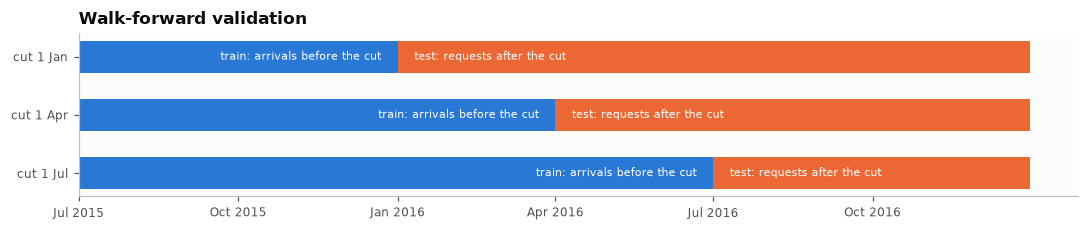

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.2))
start, end = pd.Timestamp("2015-07-01"), pd.Timestamp("2016-12-31")
for i, cut in enumerate(["2016-01-01", "2016-04-01", "2016-07-01"]):
    T = pd.Timestamp(cut)
    ax.barh(i, (T - start).days, left=0, color=P.BLUE, height=.55)
    ax.barh(i, (end - T).days, left=(T - start).days, color=P.ORANGE, height=.55)
    ax.text((T - start).days - 5, i, "train: arrivals before the cut  ", ha="right", va="center", color="white", fontsize=7.5)
    ax.text((T - start).days + 5, i, "  test: requests after the cut", ha="left", va="center", color="white", fontsize=7.5)
ax.set_yticks(range(3), ["cut 1 Jan", "cut 1 Apr", "cut 1 Jul"]); ax.invert_yaxis()
ticks = pd.date_range(start, end, freq="QS")
ax.set_xticks([(t - start).days for t in ticks], [t.strftime("%b %Y") for t in ticks])
ax.grid(False); ax.set_title("Walk-forward validation")
plt.tight_layout(); plt.show()

### Why not ordinary cross-validation?

The same LightGBM scored with random 5-fold cross-validation and with the temporal cuts:

In [4]:
rvt = pd.read_csv(R / "01_random_vs_time.csv")
rvt["validation"] = rvt.validation.str.replace("temporal cut ", "cut ")
t = rvt.pivot_table(index="validation", columns="features", values=["auc", "logloss"]).round(3)
t

auc                               logloss               
features       + post-booking columns final features + post-booking columns final features
validation                                                                                
cut 2016-01-01                  0.770          0.734                  0.509          0.545
cut 2016-04-01                  0.787          0.732                  0.489          0.538
cut 2016-07-01                  0.768          0.729                  0.487          0.516
random 5-fold                   0.899          0.874                  0.363          0.401

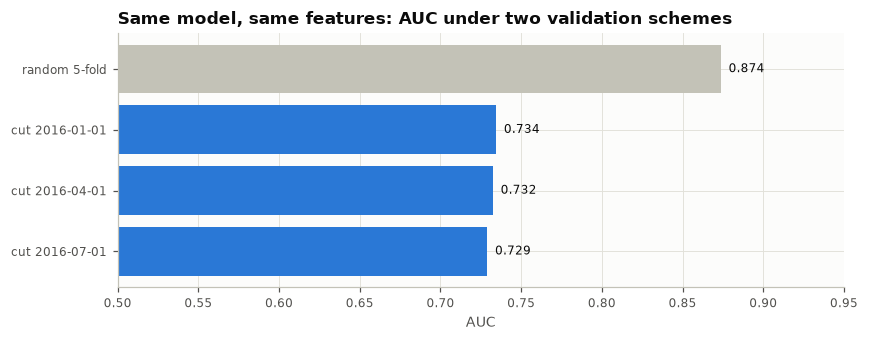

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
v = rvt[rvt.features == "final features"].set_index("validation").auc
ax.barh(v.index, v, color=[P.LIGHT] + [P.BLUE] * 3)
for i, x in enumerate(v):
    ax.text(x + .005, i, f"{x:.3f}", va="center", fontsize=8)
ax.set(xlim=(.5, .95), title="Same model, same features: AUC under two validation schemes", xlabel="AUC")
ax.invert_yaxis()
P.save(fig, "random_vs_temporal")
plt.tight_layout(); plt.show()

Random cross-validation reports **AUC 0.87**; the honest temporal estimate is **0.73**. Shuffling
mixes 2016 bookings into the training of 2015-like folds, so the model is tested on behaviour it
has already seen (the same agencies, the same groups, the same month). Every decision in this
project was taken on the temporal cuts.

## 3 · Which algorithm?

Three model families, chosen to be different from each other: **logistic regression** (linear,
fully readable), **LightGBM** and **CatBoost** (gradient-boosted trees, different handling of
categories). Plus two ways of combining them: the plain average of their logits (`avg3`) and a
**temporal stack** (`stack3`: a logistic meta-model fitted on predictions for the last four months,
made by members trained before them). An **EBM** (an additive glass-box model) is compared as well,
alone and added to the combinations; it is not part of the final model.

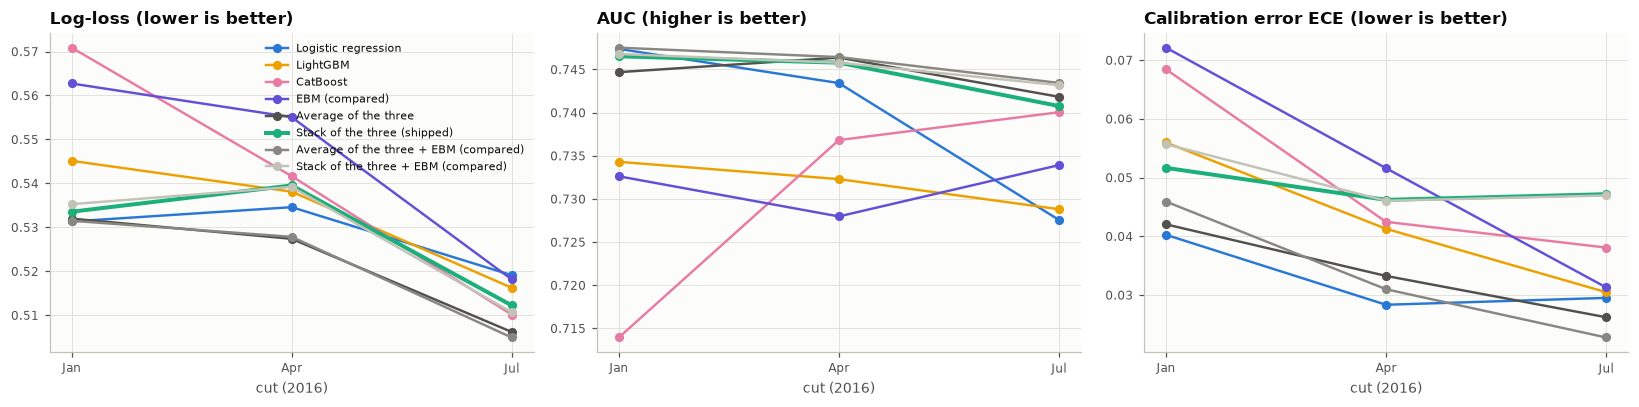

auc                              ece                          logloss                      
cut    2016-01-01 2016-04-01 2016-07-01 2016-01-01 2016-04-01 2016-07-01 2016-01-01 2016-04-01 2016-07-01
recipe                                                                                                   
lr          0.747      0.743      0.728      0.040      0.028      0.030      0.531      0.535      0.519
lgb         0.734      0.732      0.729      0.056      0.041      0.030      0.545      0.538      0.516
cb          0.714      0.737      0.740      0.068      0.042      0.038      0.571      0.542      0.510
ebm         0.733      0.728      0.734      0.072      0.052      0.031      0.563      0.555      0.518
avg3        0.745      0.746      0.742      0.042      0.033      0.026      0.532      0.527      0.506
stack3      0.747      0.746      0.741      0.052      0.046      0.047      0.534      0.540      0.512
avg4        0.748      0.746      0.743      0.046      0.031      0.023      0.531      0.528      0.505
stack4      0.747      0.746      0.743      0.056      0.046      0.047      0.535      0.539      0.511

In [6]:
alg = pd.read_csv(R / "01_algorithms.csv")
ALG_ORDER = ["lr", "lgb", "cb", "ebm", "avg3", "stack3", "avg4", "stack4"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, m, title in zip(axes, ["logloss", "auc", "ece"], ["Log-loss (lower is better)", "AUC (higher is better)",
                                                          "Calibration error ECE (lower is better)"]):
    for r in ALG_ORDER:
        x = alg[alg.recipe == r]
        ax.plot(pd.to_datetime(x.cut).dt.strftime("%b"), x[m], marker="o", color=RECIPE_COLORS[r],
                lw=2.6 if r == "stack3" else 1.6, label=RECIPE_NAMES[r])
    ax.set(title=title, xlabel="cut (2016)")
axes[0].legend(fontsize=7)
P.save(fig, "algorithms")
plt.tight_layout(); plt.show()
alg.pivot_table(index="recipe", columns="cut", values=["logloss", "auc", "ece"]).reindex(ALG_ORDER).round(3)

* **Logistic regression is a very strong baseline**: the best single model at the January and April
  cuts (log-loss 0.531, 0.535), and the best calibrated at those two cuts.
* **The average of the three** has the best log-loss at the April and July cuts (0.527, 0.506) among
  the recipes built from the shipped members, and the lowest calibration error in July (0.026).
  Diversity pays: the three families make different mistakes.
* **Single tree models** are not better than the linear model on this problem and are worse
  calibrated at the early cuts (less history, more drift).
* **The stack** ranks as well as the average (AUC within 0.001) but is less well calibrated: at
  the July cut it predicts 22% cancellations on average for an observed 27%. A meta-model fitted
  on only four months of recent outcomes inherits whatever was special about those months.
* **The EBM adds nothing measurable**: alone it is no better than logistic regression, and adding it
  to the average or to the stack changes log-loss and AUC by at most 0.002 at every cut.

### Calibration at the July cut

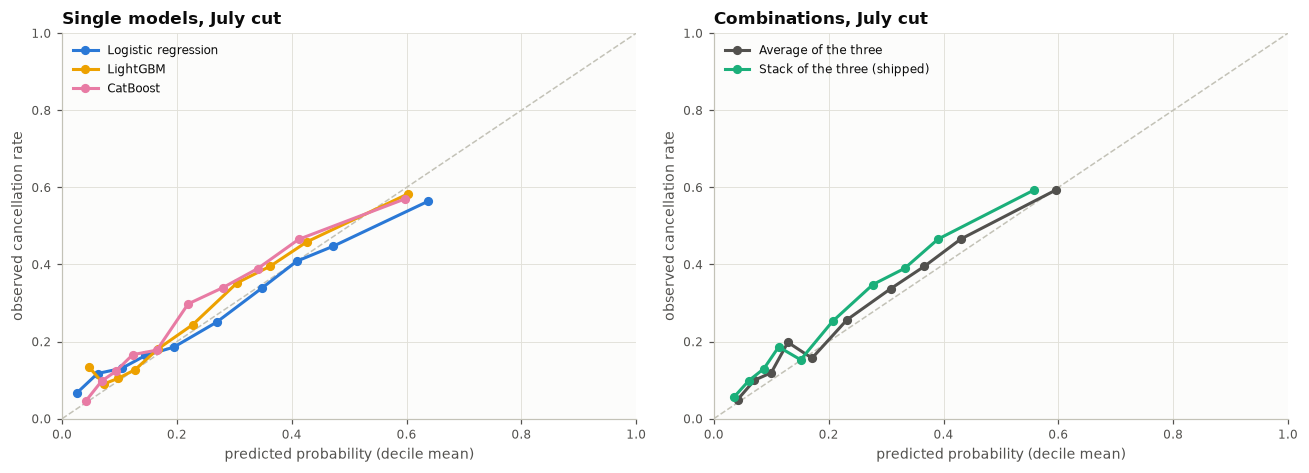

In [7]:
cal = pd.read_csv(R / "01_calibration.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, recipes in zip(axes, [["lr", "lgb", "cb"], ["avg3", "stack3"]]):
    ax.plot([0, 1], [0, 1], color=P.LIGHT, ls="--", lw=1)
    for r in recipes:
        x = cal[cal.recipe == r]
        ax.plot(x.pred, x.obs, marker="o", color=RECIPE_COLORS[r], label=RECIPE_NAMES[r])
    ax.set(xlabel="predicted probability (decile mean)", ylabel="observed cancellation rate", xlim=(0, 1), ylim=(0, 1))
    ax.legend()
axes[0].set_title("Single models, July cut"); axes[1].set_title("Combinations, July cut")
P.save(fig, "calibration")
plt.tight_layout(); plt.show()

All recipes are close to the diagonal over the whole range: the probabilities can be used as
probabilities. The stack sits slightly below the diagonal in the middle deciles, i.e. it slightly
under-predicts cancellations in the second half of 2016.

## 4 · What each design choice is worth (ablations)

Each variant changes one thing in the final recipe; LR and LightGBM, three cuts.

In [8]:
abl = pd.read_csv(R / "01_ablations.csv")
abl["calibration gap"] = abl.mean_pred - abl.mean_true
t = abl.pivot_table(index=["algo", "variant"], columns="cut", values=["logloss", "auc", "calibration gap"]).round(3)
order = ["final features", "+ country and guest history", "+ special requests", "+ all post-booking columns",
         "no recency weights", "half-life 3 months", "half-life 12 months"]
t.reindex(pd.MultiIndex.from_product([["lr", "lgb"], order]))

auc                       calibration gap                          logloss                      
cut                             2016-01-01 2016-04-01 2016-07-01      2016-01-01 2016-04-01 2016-07-01 2016-01-01 2016-04-01 2016-07-01
lr  final features                   0.748      0.743      0.728          -0.011     -0.004     -0.001      0.531      0.535      0.519
    + country and guest history      0.726      0.777      0.781          -0.206     -0.098     -0.087      0.934      0.567      0.521
    + special requests               0.775      0.785      0.750          -0.010     -0.009     -0.029      0.508      0.500      0.507
    + all post-booking columns       0.785      0.794      0.760          -0.008     -0.008     -0.034      0.499      0.490      0.496
    no recency weights               0.747      0.742      0.728          -0.010     -0.006     -0.006      0.531      0.535      0.518
    half-life 3 months               0.748      0.744      0.726          -0.010     -0.004      0.010      0.531      0.535      0.521
    half-life 12 months              0.747      0.743      0.728          -0.011     -0.005     -0.004      0.531      0.535      0.519
lgb final features                   0.734      0.732      0.729          -0.007     -0.018     -0.024      0.545      0.538      0.516
    + country and guest history      0.668      0.719      0.758          -0.202     -0.172     -0.158      1.044      0.766      0.647
    + special requests               0.756      0.778      0.765          -0.010     -0.015     -0.041      0.522      0.497      0.491
    + all post-booking columns       0.770      0.787      0.768          -0.007     -0.018     -0.038      0.509      0.489      0.487
    no recency weights               0.729      0.730      0.728          -0.003     -0.021     -0.025      0.552      0.540      0.517
    half-life 3 months               0.739      0.738      0.739          -0.007     -0.022     -0.023      0.536      0.536      0.510
    half-life 12 months              0.731      0.734      0.728          -0.007     -0.021     -0.025      0.547      0.537      0.517

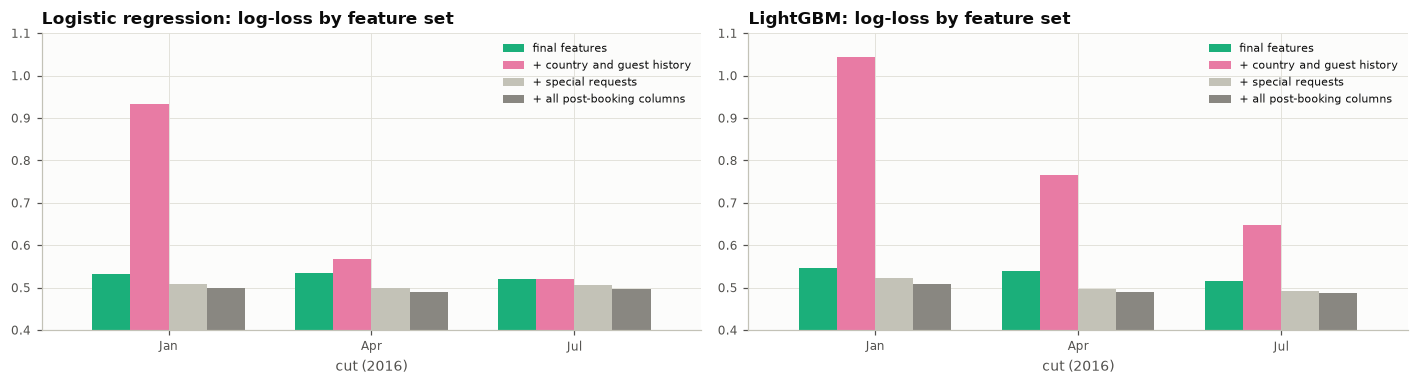

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, algo in zip(axes, ["lr", "lgb"]):
    x = abl[(abl.algo == algo) & abl.variant.isin(order[:4])]
    piv = x.pivot(index="cut", columns="variant", values="logloss")[order[:4]]
    piv.index = pd.to_datetime(piv.index).strftime("%b")
    colors = [P.OURS, P.MAGENTA, P.LIGHT, P.MUTED]
    piv.plot.bar(ax=ax, color=colors, rot=0, width=.75)
    ax.set(title=f"{RECIPE_NAMES[algo]}: log-loss by feature set", xlabel="cut (2016)", ylim=(.4, 1.1))
    ax.legend(fontsize=7)
P.save(fig, "feature_ablation")
plt.tight_layout(); plt.show()

**Drifting columns are poison for calibration.** Adding `country` and the guest-history counters
makes the January-cut predictions average 11% (LightGBM) and 11% (LR) for a true rate of 31%; the
log-loss nearly doubles (LR 0.53 → 0.93, LightGBM 0.55 → 1.04). The damage shrinks at later cuts,
as more 2016 data enters training, but never disappears. The model would have looked excellent on
a random split and failed in production.

**Post-booking columns would help, and are excluded anyway.** Special requests alone add about
0.03 AUC; all three post-booking columns about 0.03–0.05. That is the price of using only what a
hotel actually knows at decision time. Notebook 08 shows the revenue side of the same trade-off.

**Recency weights matter little for LR and a bit for LightGBM**; a 6-month half-life is a safe
middle ground between 3 months (slightly better for LightGBM) and none.

## 5 · From probabilities to money

Classification metrics are not the objective. Every recipe was also plugged into the policy and
replayed on 2016 (H1 = model trained before January, replayed January–June; H2 = trained before
July, replayed July–December), three within-day orders each, with a **logit shift** added to the
probabilities (positive = assume more cancellations).

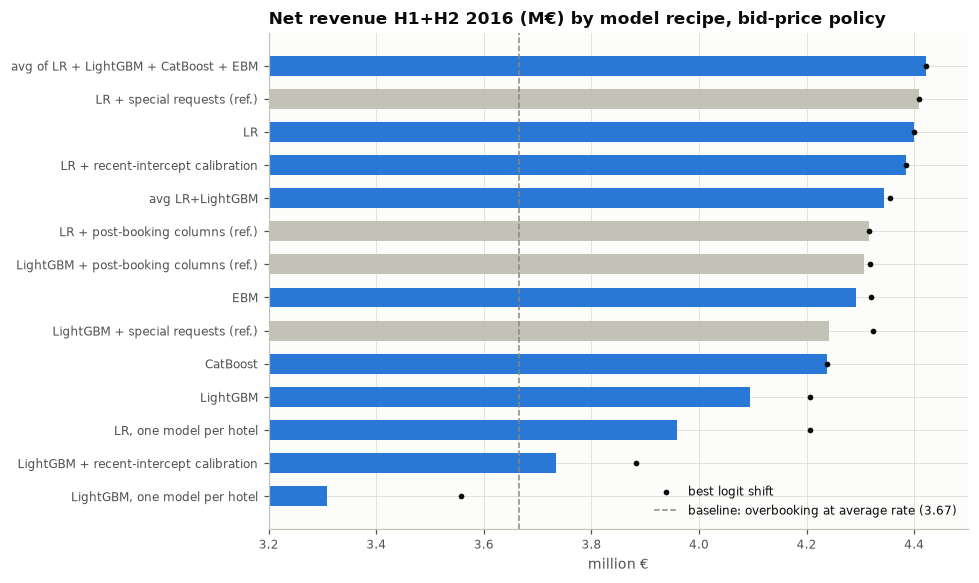

,H1+H2 at shift 0,best H1+H2 over shifts
config,,
lr+lgb+cb+ebm,4.422,4.422
ref_sr_lr,4.409,4.409
lr,4.400,4.400
lr_cal,4.385,4.385
lr+lgb,4.345,4.356
ref_full_lr,4.315,4.315
ref_full_lgb,4.306,4.318
ebm,4.292,4.320
ref_sr_lgb,4.241,4.324


In [10]:
grid = pd.read_csv(R / "02_recipe_grid.csv")
g = grid.groupby(["config", "shift", "window"]).net_M.mean().unstack("window")
g["H1+H2"] = g.H1 + g.H2
g0 = g.xs(0.0, level="shift").sort_values("H1+H2", ascending=False)
best = g.groupby(level="config")["H1+H2"].max()
NAMES = {"lr": "LR", "lgb": "LightGBM", "cb": "CatBoost", "ebm": "EBM", "lr+lgb": "avg LR+LightGBM",
         "lr+lgb+cb+ebm": "avg of LR + LightGBM + CatBoost + EBM", "lr_cal": "LR + recent-intercept calibration",
         "lgb_cal": "LightGBM + recent-intercept calibration", "lr_perhotel": "LR, one model per hotel",
         "lgb_perhotel": "LightGBM, one model per hotel", "ref_sr_lr": "LR + special requests (ref.)",
         "ref_sr_lgb": "LightGBM + special requests (ref.)", "ref_full_lr": "LR + post-booking columns (ref.)",
         "ref_full_lgb": "LightGBM + post-booking columns (ref.)"}
out = pd.DataFrame({"H1+H2 at shift 0": g0["H1+H2"], "best H1+H2 over shifts": best}).sort_values("H1+H2 at shift 0")
fig, ax = plt.subplots(figsize=(9, 5.4))
y = np.arange(len(out))
ref = out.index.str.startswith("ref_")
ax.barh(y, out["H1+H2 at shift 0"], color=np.where(ref, P.LIGHT, P.BLUE), height=.6)
ax.scatter(out["best H1+H2 over shifts"], y, color=P.INK, zorder=3, s=14, label="best logit shift")
ax.set_yticks(y, [NAMES[c] for c in out.index]); ax.set_xlim(3.2, 4.5)
ax.axvline(2.246 + 1.420, color=P.MUTED, ls="--", lw=1, label="baseline: overbooking at average rate (3.67)")
ax.set(title="Net revenue H1+H2 2016 (M€) by model recipe, bid-price policy", xlabel="million €")
ax.legend(loc="lower right")
P.save(fig, "recipe_revenue")
plt.tight_layout(); plt.show()
out.round(3).iloc[::-1]

* **Almost every recipe beats the baseline by a wide margin** (3.67M on H1+H2): most of the gain
  comes from having *a* per-booking probability plus the bid-price rule. The exception is
  LightGBM trained separately per hotel.
* **One model per hotel and the recent-intercept calibration are worse**, sometimes much worse:
  halving the data costs more than hotel-specific behaviour gains, and recalibrating on the last
  three months chases noise.
* **Revenue is not monotone in log-loss.** LightGBM's log-loss is close to LR's but it earns
  0.3M less on H1+H2 at shift 0. The policy cares about the *level* of the probabilities in the
  segments where it is choosing, not only about their ranking.
* The post-booking references show that the "cheating" columns would not even buy more revenue
  for LR (4.41 with special requests, 4.32 with all three, vs 4.40): their extra AUC does not
  translate into better acceptance decisions.

### Finalists, full year and logit shift

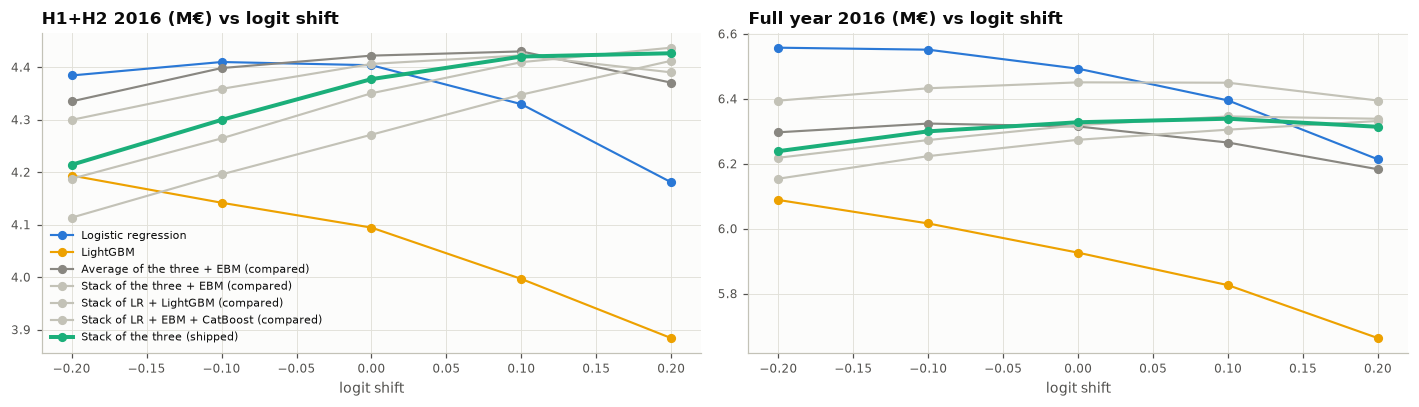

window,H1,H2,H1+H2,FY
config,,,,
avg4,2.696,1.726,4.422,6.314
stack_lr_lgb,2.700,1.706,4.406,6.450
lr,2.693,1.711,4.404,6.492
stack_lr_lgb_cb,2.683,1.694,4.377,6.328
stack4,2.658,1.692,4.350,6.318
stack_lr_ebm_cb,2.608,1.664,4.271,6.274
lgb,2.364,1.730,4.094,5.926


In [11]:
fin = pd.read_csv(R / "03_finalists.csv")
f = fin.groupby(["config", "shift", "window"]).net_M.mean().unstack("window")
f["H1+H2"] = f.H1 + f.H2
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for c in ["lr", "lgb", "avg4", "stack4", "stack_lr_lgb", "stack_lr_ebm_cb", "stack_lr_lgb_cb"]:
    x = f.xs(c, level="config")
    col = RECIPE_COLORS.get(c, P.LIGHT)
    lw = 2.6 if c == "stack_lr_lgb_cb" else 1.4
    axes[0].plot(x.index, x["H1+H2"], marker="o", color=col, lw=lw, label=RECIPE_NAMES.get(c, c))
    axes[1].plot(x.index, x["FY"], marker="o", color=col, lw=lw, label=RECIPE_NAMES.get(c, c))
axes[0].set(title="H1+H2 2016 (M€) vs logit shift", xlabel="logit shift")
axes[1].set(title="Full year 2016 (M€) vs logit shift", xlabel="logit shift")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
f.xs(0.0, level="shift")[["H1", "H2", "H1+H2", "FY"]].sort_values("H1+H2", ascending=False).round(3)

At shift 0 the top four recipes are within **0.05M (1%) on H1+H2** and 0.17M on the full year.
The noise between within-day request orders is small (standard deviation ≤ 0.01M), but there is
only **one year of out-of-time data**, so differences of this size are not reliable evidence.

### Stack weights are not stable

In [12]:
sw = pd.read_csv(R / "01_stack_weights.csv")
sw = sw[sw.recipe == "stack3"].set_index("cut")[["intercept", "lr", "lgb", "cb"]]
final = json.load(open(R / "06_additivity.json"))
sw.loc["final model (all data)"] = [final["stack_intercept"]] + [final["stack_weights"][m] for m in ["lr", "lgb", "cb"]]
sw.round(3)

,intercept,lr,lgb,cb
cut,,,,
2016-01-01,-0.187,0.467,0.134,0.345
2016-04-01,0.374,0.357,0.069,0.711
2016-07-01,-0.180,0.397,0.332,0.261
final model (all data),0.168,0.292,-0.002,0.695


The meta-model's weights move a lot from one cut to the next (CatBoost from 0.26 to 0.71,
LightGBM from 0.33 to 0.07): they describe *how this particular window weights the members*, not
a stable truth about which member is better.

## 6 · The model that shipped, with hindsight

The delivered model is the **stack of the three** (`stack3`, shift 0), retrained on all of
July 2015 – December 2016 (`python -m src.build_final`). The offline evidence, read honestly:

| | Logistic regression | Average of the three | Stack of the three (shipped) |
|---|---|---|---|
| Log-loss, July cut | 0.519 | **0.506** | 0.512 |
| ECE, July cut | 0.030 | **0.026** | 0.047 |
| Revenue H1+H2, shift 0 | 4.404 | not replayed | 4.377 |
| Revenue full year, shift 0 | **6.492** | not replayed | 6.328 |
| Explainability | direct | additive members | additive members (notebook 09) |

All of them are far above the baselines and within the noise of a single validation year. The plain
**average of the three** has better log-loss and calibration than the stack at every cut, with no
meta-model to fit, and is the recipe to try first in a next iteration (its revenue was not replayed
here). The lesson generalises: with one year of out-of-time data and drift, a learned combiner should
beat a simple average by a clear margin before it is preferred.